# Lab assignment №1, part 2

This lab assignment consists of several parts. You are supposed to make some transformations, train some models, estimate the quality of the models and explain your results.

Several comments:
* Don't hesitate to ask questions, it's a good practice.
* No private/public sharing, please. The copied assignments will be graded with 0 points.
* Blocks of this lab will be graded separately.

__*This is the second part of the assignment. First and third parts are waiting for you in the same directory.*__

## Part 2. Data preprocessing, model training and evaluation.

### 1. Reading the data
Today we work with the [dataset](https://archive.ics.uci.edu/ml/datasets/Statlog+%28Vehicle+Silhouettes%29), describing different cars for multiclass ($k=4$) classification problem. The data is available below.

In [1]:
# If on colab, uncomment the following lines

# ! wget https://raw.githubusercontent.com/girafe-ai/ml-course/22f_made/homeworks/lab01_ml_pipeline/car_data.csv

--2026-11-08 16:42:24--  https://raw.githubusercontent.com/girafe-ai/ml-course/22f_made/homeworks/lab01_ml_pipeline/car_data.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 58374 (57K) [text/plain]
Saving to: ‘car_data.csv’

car_data.csv        100%[===================>]  57.01K  --.-KB/s    in 0.01s   

2026-11-08 16:42:24 (4.36 MB/s) - ‘car_data.csv’ saved [58374/58374]



In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

dataset = pd.read_csv('car_data.csv', delimiter=',', header=None).values
data = dataset[:, :-1].astype(int)
target = dataset[:, -1]

print(data.shape, target.shape)

X_train, X_test, y_train, y_test = train_test_split(data, target, test_size=0.35)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(846, 19) (846,)
(549, 19) (549,) (297, 19) (297,)


To get some insights about the dataset, `pandas` might be used. The `train` part is transformed to `pd.DataFrame` below.

In [3]:
X_train_pd = pd.DataFrame(X_train)

# First 15 rows of our dataset.
X_train_pd.head(15)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
0,374,87,36,53,117,58,4,118,57,17,125,138,205,138,85,9,15,180,183
1,491,97,45,76,175,60,9,157,42,20,149,180,370,169,63,16,12,198,206
2,101,95,42,85,174,66,9,153,44,19,144,168,347,150,65,11,5,196,204
3,187,98,45,76,166,60,7,157,42,20,148,184,371,186,69,13,10,190,196
4,264,103,49,100,194,60,10,185,35,22,160,202,518,178,62,13,8,198,208
5,27,107,54,98,203,65,11,218,31,25,167,229,696,216,72,1,28,187,199
6,564,98,35,70,182,68,5,155,41,19,124,184,371,117,71,3,22,202,205
7,711,100,54,102,206,65,10,198,33,23,164,224,587,240,72,4,11,187,196
8,64,93,45,86,201,69,7,184,35,22,145,203,523,183,72,0,4,194,197
9,4,85,44,70,205,103,52,149,45,19,144,241,325,188,127,9,11,180,183


Methods `describe` and `info` deliver some useful information.

In [4]:
X_train_pd.describe()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
count,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000,549.000000
mean,412.635701,93.825137,45.012750,82.326047,169.965392,62.018215,8.805100,169.211293,40.774135,20.617486,148.679417,189.134791,441.204007,175.271403,72.418944,6.469945,12.213115,189.096539,195.825137
std,238.705218,8.227293,5.981558,15.520803,33.990508,8.443438,5.150676,32.625320,7.544514,2.558681,13.928885,30.924503,174.387003,31.732244,7.744511,4.872977,8.858999,6.179476,7.465885
min,1.000000,73.000000,34.000000,47.000000,110.000000,47.000000,3.000000,114.000000,26.000000,17.000000,121.000000,132.000000,192.000000,109.000000,60.000000,0.000000,0.000000,176.000000,181.000000
25%,207.000000,88.000000,40.000000,70.000000,141.000000,57.000000,7.000000,148.000000,33.000000,19.000000,138.000000,168.000000,322.000000,151.000000,67.000000,3.000000,5.000000,184.000000,191.000000
50%,410.000000,93.000000,45.000000,80.000000,169.000000,61.000000,8.000000,157.000000,43.000000,20.000000,147.000000,179.000000,365.000000,174.000000,71.000000,6.000000,11.000000,189.000000,197.000000
75%,611.000000,100.000000,49.000000,98.000000,197.000000,66.000000,10.000000,198.000000,46.000000,23.000000,160.000000,217.000000,586.000000,198.000000,76.000000,9.000000,17.000000,193.000000,201.000000
max,843.000000,119.000000,59.000000,112.000000,333.000000,138.000000,55.000000,265.000000,59.000000,29.000000,186.000000,320.000000,1018.000000,268.000000,135.000000,22.000000,40.000000,206.000000,211.000000


In [5]:
X_train_pd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 549 entries, 0 to 548
Data columns (total 19 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   0       549 non-null    int64
 1   1       549 non-null    int64
 2   2       549 non-null    int64
 3   3       549 non-null    int64
 4   4       549 non-null    int64
 5   5       549 non-null    int64
 6   6       549 non-null    int64
 7   7       549 non-null    int64
 8   8       549 non-null    int64
 9   9       549 non-null    int64
 10  10      549 non-null    int64
 11  11      549 non-null    int64
 12  12      549 non-null    int64
 13  13      549 non-null    int64
 14  14      549 non-null    int64
 15  15      549 non-null    int64
 16  16      549 non-null    int64
 17  17      549 non-null    int64
 18  18      549 non-null    int64
dtypes: int64(19)
memory usage: 81.6 KB


### 2. Machine Learning pipeline
Here you are supposed to perform the desired transformations. Please, explain your results briefly after each task.

#### 2.0. Data preprocessing
* Make some transformations of the dataset (if necessary). Briefly explain the transformations

Посмотрим, есть ли дубликаты в наборе данных

In [16]:
df = pd.DataFrame(data)
df["target"] = pd.Series(target)

In [17]:
print("Number of duplicates:", df.duplicated().sum())

Number of duplicates: 0


Дубликатов нет

Проверим типы столбцов датасета

In [18]:
print(df.dtypes)

0          int64
1          int64
2          int64
3          int64
4          int64
5          int64
6          int64
7          int64
8          int64
9          int64
10         int64
11         int64
12         int64
13         int64
14         int64
15         int64
16         int64
17         int64
18         int64
target    object
dtype: object


Все параметры числовые

Посмотрим на распределение классов

In [19]:
print(df["target"].value_counts(normalize=True))

target
bus     0.257683
saab    0.256501
opel    0.250591
van     0.235225
Name: proportion, dtype: float64


Все классы сбалансированы

Дальше буду использовать StandardScaler в тех методах, где он нужен

#### 2.1. Basic logistic regression
* Find optimal hyperparameters for logistic regression with cross-validation on the `train` data (small grid/random search is enough, no need to find the *best* parameters).

* Estimate the model quality with `f1` and `accuracy` scores.
* Plot a ROC-curve for the trained model. For the multiclass case you might use `scikitplot` library (e.g. `scikitplot.metrics.plot_roc(test_labels, predicted_proba)`).

*Note: please, use the following hyperparameters for logistic regression: `multi_class='multinomial'`, `solver='saga'` `tol=1e-3` and ` max_iter=500`.*

In [21]:
!pip install scikit-plot

In [33]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import f1_score, accuracy_score

import numpy as np
import scipy

scipy.interp = np.interp
np.float = float
np.int = int
np.in1d = np.isin

import scikitplot as skplt
import matplotlib.pyplot as plt

In [37]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        solver='saga',
        tol=1e-3,
        max_iter=500,
        random_state=42
    ))
])

hyper_params = {
    'model__C': [0.001, 0.01, 0.1, 0.5, 1, 10],
    'model__penalty': ['l1', 'l2']
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=hyper_params,
    cv=cv,
    scoring='f1_macro'
)

grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_

print("Best parameters:", grid_search.best_params_)
print("Best f1-score on CV:", grid_search.best_score_)

Best parameters: {'model__C': 10, 'model__penalty': 'l1'}
Best f1-score on CV: 0.8023163434454457


In [38]:
y_pred = best_model.predict(X_test)

f1 = f1_score(y_test, y_pred, average='macro')
accuracy = accuracy_score(y_test, y_pred)

print(f"F1-score(macro): {f1:.4f}")
print(f"Accuracy: {accuracy:.4f}")

F1-score(macro): 0.7684
Accuracy: 0.7576


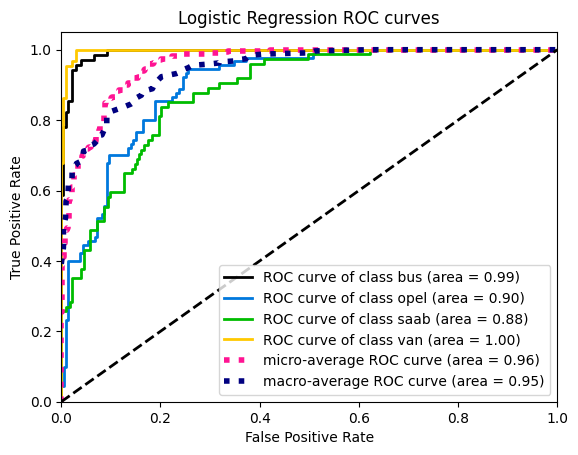

In [39]:
proba = best_model.predict_proba(X_test)

skplt.metrics.plot_roc(
    y_test,
    proba,
    title='Logistic Regression ROC curves',
)

plt.show()

Поскольку классы хорошо сбалансированы, в таком случае мы можем использовать ROC-AUC для анализа качества модели.

Если смотреть на метрики F1-score(macro): 0.7684 и Accuracy: 0.7576, можно сделать вывод, что модель классифицирует транспорт чуть выше среднего.

По ROC-AUC видно, что классы bus и van модель различает почти идеально, в то время как классы saab и opel она различает чуть хуже.

#### 2.2. PCA: explained variance plot
* Apply the PCA to the train part of the data. Build the explaided variance plot.

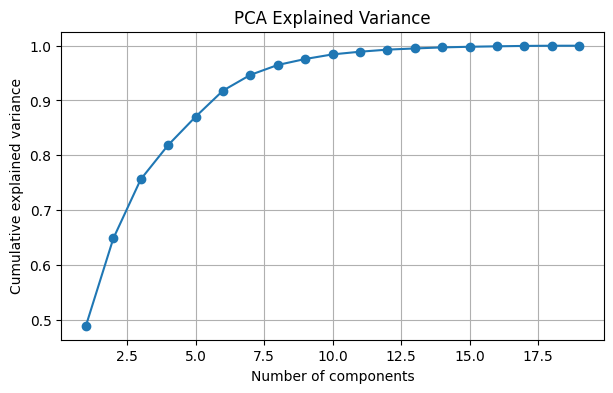

In [62]:
from sklearn.decomposition import PCA

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

pca = PCA()
X_train_pca = pca.fit_transform(X_train_scaled)

explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.title('PCA Explained Variance')
plt.grid()
plt.show()

#### 2.3. PCA trasformation
* Select the appropriate number of components. Briefly explain your choice. Should you normalize the data?

*Use `fit` and `transform` methods to transform the `train` and `test` parts.*

Можно оставить 8 компанент, что соответствует 95% накопленной объяснённой дисперсии.

Поскольку признаки имеют разные масштабы, перед PCA используется StandardScaler.

In [56]:
n_components = 8

pca_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=n_components))
])

X_train_pca = pca_pipeline.fit_transform(X_train)
X_test_pca = pca_pipeline.transform(X_test)

print("Train shape:", X_train_pca.shape)
print("Test shape:", X_test_pca.shape)

Train shape: (549, 8)
Test shape: (297, 8)


**Note: From this point `sklearn` [Pipeline](https://scikit-learn.org/stable/modules/compose.html) might be useful to perform transformations on the data. Refer to the [docs](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html) for more information.**

#### 2.4. Logistic regression on PCA-preprocessed data.
* Find optimal hyperparameters for logistic regression with cross-validation on the transformed by PCA `train` data.

* Estimate the model quality with `f1` and `accuracy` scores.
* Plot a ROC-curve for the trained model. For the multiclass case you might use `scikitplot` library (e.g. `scikitplot.metrics.plot_roc(test_labels, predicted_proba)`).

*Note: please, use the following hyperparameters for logistic regression: `multi_class='multinomial'`, `solver='saga'` and `tol=1e-3`*

In [57]:
model = LogisticRegression(
    solver='saga',
    tol=1e-3,
    max_iter=500,
    random_state=42
)

hyper_params = {
    'C': [0.001, 0.01, 0.1, 0.5, 1, 10],
    'penalty': ['l1', 'l2']
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=model,
    param_grid=hyper_params,
    cv=cv,
    scoring='f1_macro'
)

grid_search.fit(X_train_pca, y_train)
best_model_pca = grid_search.best_estimator_

print("Best parameters:", grid_search.best_params_)
print("Best f1-score on CV:", grid_search.best_score_)

Best parameters: {'C': 1, 'penalty': 'l2'}
Best f1-score on CV: 0.6184843294985957


In [58]:
y_pred = best_model_pca.predict(X_test_pca)

f1 = f1_score(y_test, y_pred, average='macro')
accuracy = accuracy_score(y_test, y_pred)

print(f"F1-score(macro): {f1:.4f}")
print(f"Accuracy: {accuracy:.4f}")

F1-score(macro): 0.6224
Accuracy: 0.6229


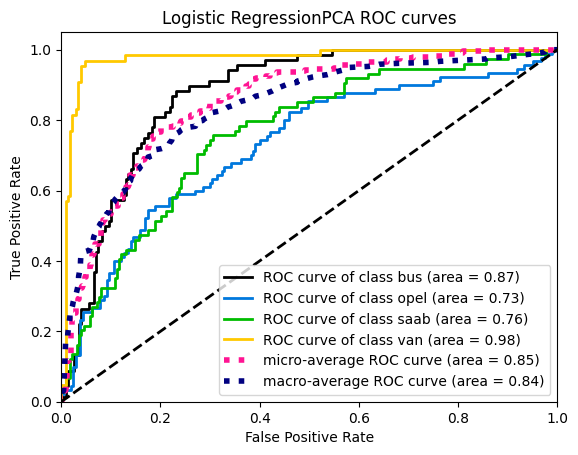

In [59]:
proba = best_model_pca.predict_proba(X_test_pca)

skplt.metrics.plot_roc(
    y_test,
    proba,
    title='Logistic RegressionPCA ROC curves',
)

plt.show()

Модель стала работать сильно хуже, что не удивительно, так как мы теряем часть информации. При этом, Для набора данных с маленьким числом параметров pca не дает большого выигрыша по вычислениям.

#### 2.5. Decision tree
* Now train a desicion tree on the same data. Find optimal tree depth (`max_depth`) using cross-validation.

* Measure the model quality using the same metrics you used above.

In [60]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(
    random_state=42
)

hyper_params = {
    'max_depth': [1, 2, 4, 6, 8, 10],
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=model,
    param_grid=hyper_params,
    cv=cv,
    scoring='f1_macro'
)

grid_search.fit(X_train, y_train)
best_model_tree = grid_search.best_estimator_

print("Best parameters:", grid_search.best_params_)
print("Best f1-score on CV:", grid_search.best_score_)

Best parameters: {'max_depth': 8}
Best f1-score on CV: 0.678347889789569


In [61]:
y_pred = best_model_tree.predict(X_test)

f1 = f1_score(y_test, y_pred, average='macro')
accuracy = accuracy_score(y_test, y_pred)

print(f"F1-score(macro): {f1:.4f}")
print(f"Accuracy: {accuracy:.4f}")

F1-score(macro): 0.6556
Accuracy: 0.6498


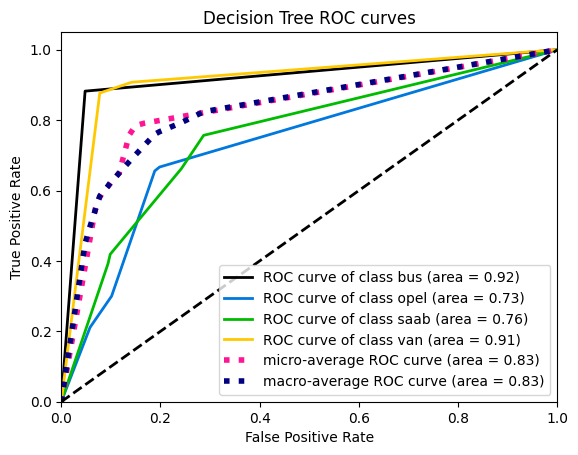

In [64]:
proba = best_model_tree.predict_proba(X_test)

skplt.metrics.plot_roc(
    y_test,
    proba,
    title='Decision Tree ROC curves',
)

plt.show()

Решающее дерево работает хуже, чем лог регрессия, так как само по себе это слабая модель, склонная к переобучению.

#### 2.6. Bagging.
Here starts the ensembling part.

First we will use the __Bagging__ approach. Build an ensemble of $N$ algorithms varying N from $N_{min}=2$ to $N_{max}=100$ (with step 5).

We will build two ensembles: of logistic regressions and of decision trees.

*Comment: each ensemble should be constructed from models of the same family, so logistic regressions should not be mixed up with decision trees.*


*Hint 1: To build a __Bagging__ ensebmle varying the ensemble size efficiently you might generate $N_{max}$ subsets of `train` data (of the same size as the original dataset) using bootstrap procedure once. Then you train a new instance of logistic regression/decision tree with optimal hyperparameters you estimated before on each subset (so you train it from scratch). Finally, to get an ensemble of $N$ models you average the $N$ out of $N_{max}$ models predictions.*

*Hint 2: sklearn might help you with this taks. Some appropriate function/class might be out there.*

* Plot `f1` and `accuracy` scores plots w.r.t. the size of the ensemble.

* Briefly analyse the plot. What is the optimal number of algorithms? Explain your answer.

* How do you think, are the hyperparameters for the decision trees you found in 2.5 optimal for trees used in ensemble?

In [65]:
from sklearn.base import clone
from sklearn.utils import resample

ensemble_sizes = range(2, 100, 5)
N_max = max(ensemble_sizes)
classes = np.unique(y_train)

bootstrap_samples = [
    resample(
        np.arange(len(X_train)),
        replace=True,
        n_samples=len(X_train),
        random_state=i
    )
    for i in range(N_max)
]

In [68]:
def bagging_eval(base_model):
    models_proba = []

    for indices in bootstrap_samples:
        model = clone(base_model)
        model.fit(X_train[indices], y_train[indices])

        proba = model.predict_proba(X_test)
        models_proba.append(proba)

    f1_scores = []
    accuracy_scores = []

    for n in ensemble_sizes:
        avg_proba = np.mean(models_proba[:n], axis=0)
        y_pred = classes[np.argmax(avg_proba, axis=1)]

        f1_scores.append(
            f1_score(y_test, y_pred, average='macro')
        )
        accuracy_scores.append(
            accuracy_score(y_test, y_pred)
        )

    return f1_scores, accuracy_scores

In [69]:
logreg_f1, logreg_acc = bagging_eval(best_model)
tree_f1, tree_acc = bagging_eval(best_model_tree)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


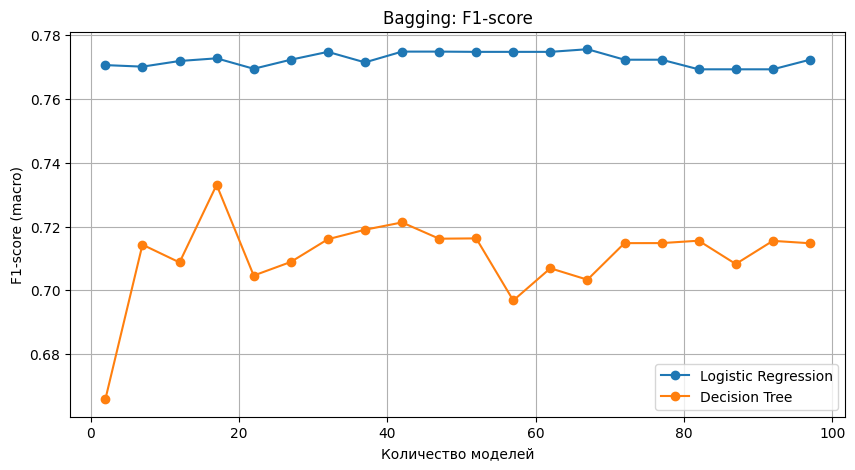

In [70]:
plt.figure(figsize=(10, 5))

plt.plot(ensemble_sizes, logreg_f1, marker='o', label='Logistic Regression')
plt.plot(ensemble_sizes, tree_f1, marker='o', label='Decision Tree')

plt.xlabel('Количество моделей')
plt.ylabel('F1-score (macro)')
plt.title('Bagging: F1-score')
plt.legend()
plt.grid()
plt.show()

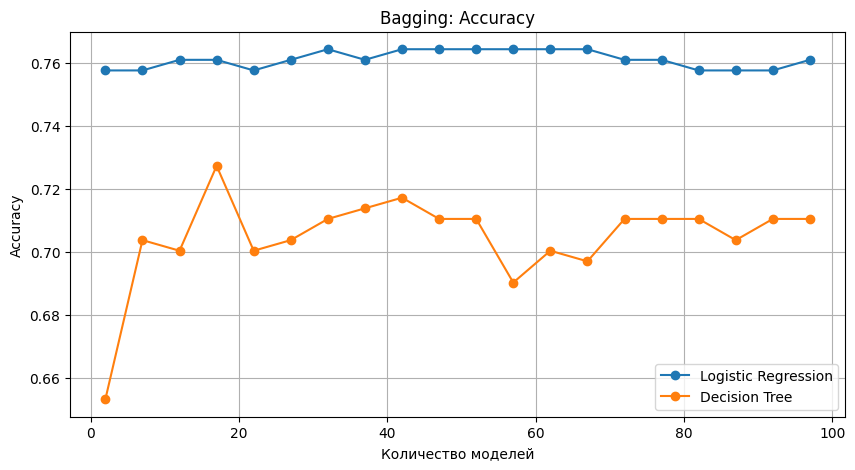

In [71]:
plt.figure(figsize=(10, 5))

plt.plot(ensemble_sizes, logreg_acc, marker='o', label='Logistic Regression')
plt.plot(ensemble_sizes, tree_acc, marker='o', label='Decision Tree')

plt.xlabel('Количество моделей')
plt.ylabel('Accuracy')
plt.title('Bagging: Accuracy')
plt.legend()
plt.grid()
plt.show()

Для лог. регрессии качество не меняется с ростом ансамбля, так как одна модель сама по себе достаточно устойчива.

Для деревьев лучшее число моделей в ансамбле - 17, судя по графику.

Лучшие гиперпараметры одиночной модели не обязательно являются таковыми для моделей ансамбля. Например, В бэггинге на деревьях результат моделей усредняется, чтобы уменьшить дисперсию, поэтому каждое дерево должно быть глубоким, в то время как одиночное дерево при большой глубине склонно к переобучению.

#### 2.7. Random Forest
Now we will work with the Random Forest (its `sklearn` implementation).

* * Plot `f1` and `accuracy` scores plots w.r.t. the number of trees in Random Forest.

* What is the optimal number of trees you've got? Is it different from the optimal number of logistic regressions/decision trees in 2.6? Explain the results briefly.

In [76]:
from sklearn.ensemble import RandomForestClassifier

ensemble_sizes = range(2, 100, 5)

f1_scores = []
accuracy_scores = []

for n in ensemble_sizes:
    rf = RandomForestClassifier(
        n_estimators=n,
        random_state=42,
    )

    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_test)

    f1_scores.append(f1_score(y_test, y_pred, average='macro'))
    accuracy_scores.append(accuracy_score(y_test, y_pred))

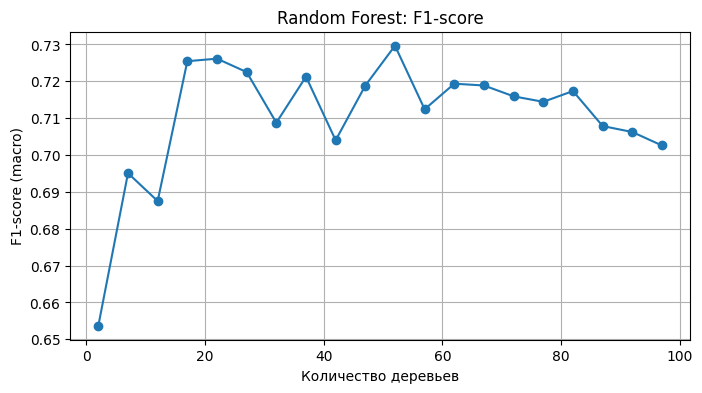

In [77]:
plt.figure(figsize=(8, 4))
plt.plot(ensemble_sizes, f1_scores, marker='o')
plt.xlabel('Количество деревьев')
plt.ylabel('F1-score (macro)')
plt.title('Random Forest: F1-score')
plt.grid()
plt.show()

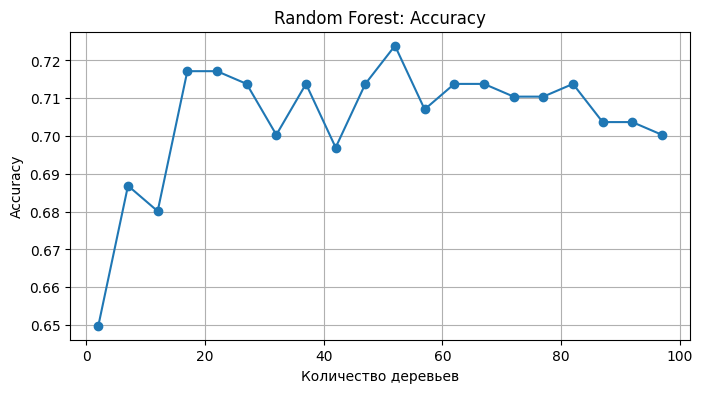

In [78]:
plt.figure(figsize=(8, 4))
plt.plot(ensemble_sizes, accuracy_scores, marker='o')
plt.xlabel('Количество деревьев')
plt.ylabel('Accuracy')
plt.title('Random Forest: Accuracy')
plt.grid()
plt.show()

In [79]:
rf_best_n = list(ensemble_sizes)[np.argmax(f1_scores)]

print("Optimal number of trees:", best_n)
print("Best F1-score:", max(f1_scores))
print("Accuracy:", accuracy_scores[np.argmax(f1_scores)])

Optimal number of trees: 52
Best F1-score: 0.7296405994997488
Accuracy: 0.7239057239057239


Качество классификации случайного леса такое же, как бэггинга на деревьях, при этом он использует большее чиссло моделей в оптимальном случае - 52.

#### 2.8. Learning curve
Your goal is to estimate, how does the model behaviour change with the increase of the `train` dataset size.

* Split the training data into 10 equal (almost) parts. Then train the models from above (Logistic regression, Desicion Tree, Random Forest) with optimal hyperparameters you have selected on 1 part, 2 parts (combined, so the train size in increased by 2 times), 3 parts and so on.

* Build a plot of `accuracy` and `f1` scores on `test` part, varying the `train` dataset size (so the axes will be score - dataset size.

* Analyse the final plot. Can you make any conlusions using it?

In [81]:
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
parts = [indices for _, indices in skf.split(X_train, y_train)]

models = {
    'Logistic Regression': clone(best_model),
    'Decision Tree': clone(best_model_tree),
    'Random Forest': RandomForestClassifier(
        n_estimators=best_n,
        random_state=42,
    )
}

results = {}

for name, model in models.items():
    results[name] = {'f1': [], 'accuracy': []}

    for i in range(1, 11):
        indices = np.concatenate(parts[:i])

        model_i = clone(model)
        model_i.fit(X_train[indices], y_train[indices])

        y_pred = model_i.predict(X_test)

        results[name]['f1'].append(
            f1_score(y_test, y_pred, average='macro')
        )
        results[name]['accuracy'].append(
            accuracy_score(y_test, y_pred)
        )

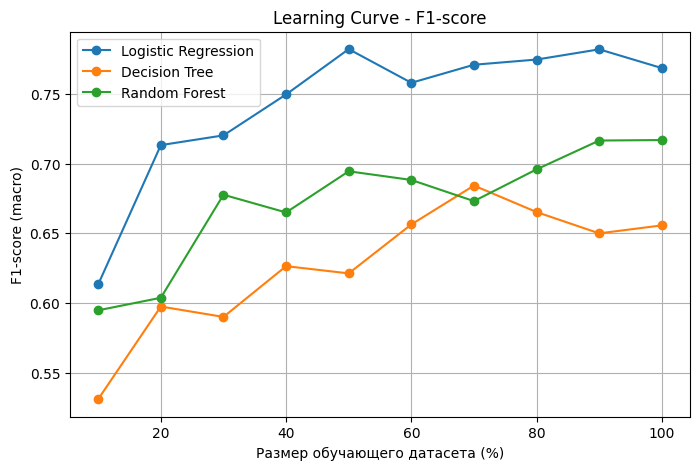

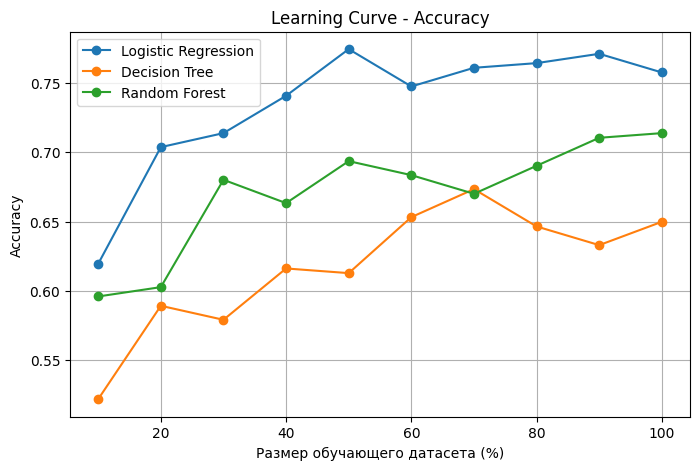

In [83]:
percentages = np.arange(10, 101, 10)

plt.figure(figsize=(8, 5))

for name in models:
    plt.plot(percentages, results[name]['f1'], marker='o', label=name)

plt.xlabel('Размер обучающего датасета (%)')
plt.ylabel('F1-score (macro)')
plt.title('Learning Curve - F1-score')
plt.legend()
plt.grid()
plt.show()


plt.figure(figsize=(8, 5))

for name in models:
    plt.plot(percentages, results[name]['accuracy'], marker='o', label=name)

plt.xlabel('Размер обучающего датасета (%)')
plt.ylabel('Accuracy')
plt.title('Learning Curve - Accuracy')
plt.legend()
plt.grid()
plt.show()

По графикам видно:
- для лог. регрессии лучшее качество модели достигается на половине датасета;
- Качество случайного леса продолжает расти вместе с ростом выборки до конца, что не удивительно, так как большой тренировочный набор дает больше случайности;
- Качество решающего дерева перестает расти после 70% выборки. Скорее всего это связанно с нестабильностью решающих деревьев.

#### 2.9. Boosting
Your goal is to build a boosting ensemble using xgboost, CatBoost or lightgbm package.
Please, do not use the sklearn API for these models.

Find optimal number of decision trees in the boosting ensembe using grid search or other methods.
Please, explain your answer.

In [84]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 20.6 MB/s  0:00:04


In [115]:
from catboost import CatBoostClassifier

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

model = CatBoostClassifier(
    iterations=1000,
    learning_rate=0.05,
    depth=6,
    loss_function='MultiClass',
    eval_metric='MultiClass',
    random_seed=42,
    verbose=0,
    early_stopping_rounds=50
)

model.fit(
    X_fit,
    y_fit,
    eval_set=(X_val, y_val),
    use_best_model=True
)

best_iterations = model.get_best_iteration() + 1
print("Optimal number of trees:", best_iterations)

Optimal number of trees: 502


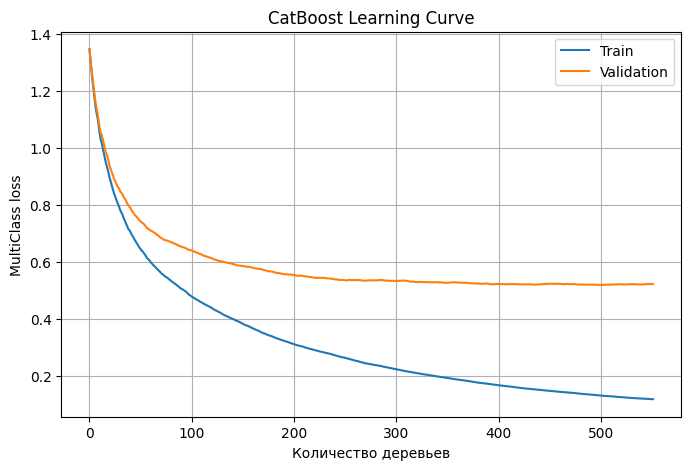

In [116]:
evals = model.get_evals_result()

plt.figure(figsize=(8, 5))

plt.plot(evals['learn']['MultiClass'], label='Train')
plt.plot(evals['validation']['MultiClass'], label='Validation')

plt.xlabel('Количество деревьев')
plt.ylabel('MultiClass loss')
plt.title('CatBoost Learning Curve')
plt.legend()
plt.grid()
plt.show()

In [117]:
catboost_model = CatBoostClassifier(
    iterations=best_iterations,
    learning_rate=0.05,
    depth=6,
    loss_function='MultiClass',
    random_seed=42,
    verbose=False
)

catboost_model.fit(X_train, y_train)

y_pred = catboost_model.predict(X_test).ravel()

print("F1-score (macro):", f1_score(y_test, y_pred, average='macro'))
print("Accuracy:", accuracy_score(y_test, y_pred))

F1-score (macro): 0.7599661405420561
Accuracy: 0.7508417508417509


Самое оптимальное число итераций - 502. Это число было найдено при помощи ранней остановке по валидации.

В итоге бустинг дал наиболее приближенный результат к лог. регрессии из всех ансамблей, но при этом все еще хуже нее, так как бустинги хорошо работают на наборах данных с большим числом объектов и признаков.